# Supply Chain & Product Demand Analysis

## Project Overview

This project analyses historical product demand across multiple warehouses and product categories to identify demand patterns, seasonal trends, product performance and demand variability.

## Business Objectives

- Analyse historical product demand and growth trends.
- Identify seasonal and monthly demand patterns.
- Identify high-demand and low-demand products.
- Compare demand across warehouses and product categories.
- Classify products using ABC and XYZ analysis.
- Identify products with high demand variability.
- Provide actionable insights to support inventory management and supply chain planning.

## Tools and Technologies

- Python (Pandas, NumPy, Matplotlib, Seaborn)
- SQL (DuckDB)
- Power BI (Power Query, DAX)
- Jupyter Notebook
- GitHub

## Data Source

[Historical Product Demand Dataset – Kaggle](https://www.kaggle.com/datasets/felixzhao/productdemandforecasting)

# Phase 1: Data understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Historical Product Demand.csv')
df.head()

,Product_Code,Warehouse,Product_Category,Date,Order_Demand
0,Product_0993,Whse_J,Category_028,2012/7/27,100
1,Product_0979,Whse_J,Category_028,2012/1/19,500
2,Product_0979,Whse_J,Category_028,2012/2/3,500
3,Product_0979,Whse_J,Category_028,2012/2/9,500
4,Product_0979,Whse_J,Category_028,2012/3/2,500


In [3]:
df.shape

(1048575, 5)

In [4]:
df.columns

Index(['Product_Code', 'Warehouse', 'Product_Category', 'Date',
       'Order_Demand'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype 
---  ------            --------------    ----- 
 0   Product_Code      1048575 non-null  object
 1   Warehouse         1048575 non-null  object
 2   Product_Category  1048575 non-null  object
 3   Date              1037336 non-null  object
 4   Order_Demand      1048575 non-null  object
dtypes: object(5)
memory usage: 40.0+ MB


In [6]:
df.isnull().sum()

Product_Code            0
Warehouse               0
Product_Category        0
Date                11239
Order_Demand            0
dtype: int64

In [7]:
(df.isnull().mean() * 100).round(2)

Product_Code        0.00
Warehouse           0.00
Product_Category    0.00
Date                1.07
Order_Demand        0.00
dtype: float64

In [8]:
df.duplicated().sum()

np.int64(122423)

In [9]:
df.nunique()

Product_Code        2160
Warehouse              4
Product_Category      33
Date                1729
Order_Demand        3828
dtype: int64

In [10]:
df['Warehouse'].unique()

array(['Whse_J', 'Whse_S', 'Whse_C', 'Whse_A'], dtype=object)

In [11]:
df['Product_Category'].unique()

array(['Category_028', 'Category_006', 'Category_001', 'Category_019',
       'Category_005', 'Category_030', 'Category_032', 'Category_011',
       'Category_033', 'Category_007', 'Category_015', 'Category_021',
       'Category_024', 'Category_026', 'Category_023', 'Category_022',
       'Category_009', 'Category_003', 'Category_004', 'Category_018',
       'Category_020', 'Category_013', 'Category_008', 'Category_017',
       'Category_031', 'Category_025', 'Category_010', 'Category_029',
       'Category_012', 'Category_002', 'Category_014', 'Category_027',
       'Category_016'], dtype=object)

In [12]:
df.describe(include='all')

,Product_Code,Warehouse,Product_Category,Date,Order_Demand
count,1048575,1048575,1048575,1037336,1048575
unique,2160,4,33,1729,3828
top,Product_1359,Whse_J,Category_019,2013/9/27,1000
freq,16936,764447,481099,2075,112682


### Initial Data Observations

- The dataset contains 1,048,575 records and 5 columns.
- There are 2,160 unique products distributed across 33 product categories and 4 warehouses.
- All columns are initially stored as object data types.
- The Date column contains 11,239 missing values.
- There are 122,423 identical duplicate records that require further investigation.
- The Date and Order_Demand columns require data type conversion.
- Further data validation is required before conducting exploratory data analysis.

# Phase 2: Data Cleaning and Preprocessing

In [13]:
for col in df.columns:
    print(col, (df[col].dropna() != df[col].dropna().str.strip()).sum())

Product_Code 0
Warehouse 0
Product_Category 0
Date 0
Order_Demand 1038106


In [14]:
df['Order_Demand'] = df['Order_Demand'].str.strip()

In [15]:
df[df['Order_Demand'].str.contains(r'\(', na=False)].head(10)

,Product_Code,Warehouse,Product_Category,Date,Order_Demand
112290,Product_2169,Whse_A,Category_024,2012/8/9,(1)
112307,Product_2132,Whse_A,Category_009,2012/11/1,(24)
112308,Product_2144,Whse_A,Category_009,2012/11/1,(24)
112356,Product_2118,Whse_A,Category_009,2012/3/7,(50)
112357,Product_2120,Whse_A,Category_009,2012/3/7,(100)
112360,Product_1794,Whse_A,Category_024,2012/6/28,(1)
112378,Product_1461,Whse_A,Category_019,2012/5/24,(150)
112441,Product_0935,Whse_A,Category_006,2012/7/19,(1000)
112563,Product_1544,Whse_A,Category_019,2012/10/12,(2500)
112610,Product_0982,Whse_A,Category_028,2012/7/19,(5000)


In [16]:
df['Order_Demand'] = df['Order_Demand'].str.replace(
    r'^\((\d+)\)$', r'-\1', regex=True
)

df['Order_Demand'] = pd.to_numeric(df['Order_Demand'])

In [17]:
df['Date'] = pd.to_datetime(df['Date'], format='%Y/%m/%d')

In [18]:
df.dtypes

Product_Code                object
Warehouse                   object
Product_Category            object
Date                datetime64[ns]
Order_Demand                 int64
dtype: object

In [19]:
df[df['Order_Demand'] < 0].shape[0]

10469

In [20]:
df[df['Order_Demand'] == 0].shape[0]

28681

In [21]:
df['Order_Demand'].describe().round(2)

count    1048575.00
mean        4867.43
std        28933.46
min      -999000.00
25%           18.00
50%          300.00
75%         2000.00
max      4000000.00
Name: Order_Demand, dtype: float64

In [22]:
print('Earliest Date:', df['Date'].min())
print('Latest Date:', df['Date'].max())

Earliest Date: 2011-01-08 00:00:00
Latest Date: 2017-01-09 00:00:00


In [23]:
df['Date'].dt.year.value_counts().sort_index()

Date
2011.0       640
2012.0    203635
2013.0    218298
2014.0    216404
2015.0    209661
2016.0    188645
2017.0        53
Name: count, dtype: int64

In [24]:
missing_dates = df[df['Date'].isnull()]

missing_dates.head(10)

,Product_Code,Warehouse,Product_Category,Date,Order_Demand
45460,Product_1461,Whse_A,Category_019,NaT,10000
456373,Product_1636,Whse_A,Category_019,NaT,100
456374,Product_1461,Whse_A,Category_019,NaT,300
456375,Product_1464,Whse_A,Category_019,NaT,300
456376,Product_1388,Whse_A,Category_019,NaT,200
456377,Product_1464,Whse_A,Category_019,NaT,600
456378,Product_1402,Whse_A,Category_019,NaT,600
456379,Product_1461,Whse_A,Category_019,NaT,100
456380,Product_1539,Whse_A,Category_019,NaT,100
456381,Product_1388,Whse_A,Category_019,NaT,800


In [25]:
missing_dates['Warehouse'].value_counts()

Warehouse
Whse_A    11239
Name: count, dtype: int64

In [26]:
missing_dates['Order_Demand'].sum()

np.int64(10090)

In [27]:
df_clean = df.dropna(subset=['Date']).copy()

df_clean.shape

(1037336, 5)

In [28]:
df[df.duplicated(keep=False)].sort_values(
    ['Product_Code', 'Date']
).head(20)

,Product_Code,Warehouse,Product_Category,Date,Order_Demand
13756,Product_0001,Whse_J,Category_005,2012-05-17,100
136752,Product_0001,Whse_J,Category_005,2012-05-17,100
111344,Product_0001,Whse_A,Category_005,2012-08-23,500
111812,Product_0001,Whse_A,Category_005,2012-08-23,500
152977,Product_0001,Whse_J,Category_005,2012-10-01,300
177385,Product_0001,Whse_J,Category_005,2012-10-01,300
78747,Product_0001,Whse_J,Category_005,2012-11-14,100
80275,Product_0001,Whse_J,Category_005,2012-11-14,100
243634,Product_0001,Whse_A,Category_005,2013-05-13,1000
336389,Product_0001,Whse_A,Category_005,2013-05-13,1000


In [29]:
df[df['Order_Demand'] < 0].head(10)

,Product_Code,Warehouse,Product_Category,Date,Order_Demand
112290,Product_2169,Whse_A,Category_024,2012-08-09,-1
112307,Product_2132,Whse_A,Category_009,2012-11-01,-24
112308,Product_2144,Whse_A,Category_009,2012-11-01,-24
112356,Product_2118,Whse_A,Category_009,2012-03-07,-50
112357,Product_2120,Whse_A,Category_009,2012-03-07,-100
112360,Product_1794,Whse_A,Category_024,2012-06-28,-1
112378,Product_1461,Whse_A,Category_019,2012-05-24,-150
112441,Product_0935,Whse_A,Category_006,2012-07-19,-1000
112563,Product_1544,Whse_A,Category_019,2012-10-12,-2500
112610,Product_0982,Whse_A,Category_028,2012-07-19,-5000


In [30]:
df.groupby(
    np.select(
        [df['Order_Demand'] < 0, df['Order_Demand'] == 0],
        ['Negative', 'Zero'],
        default='Positive'
    )
)['Order_Demand'].agg(['count', 'sum'])

,count,sum
Negative,10469,-20735500
Positive,1009425,5124597821
Zero,28681,0


In [31]:
df_clean['Demand_Type'] = np.select(
    [
        df_clean['Order_Demand'] < 0,
        df_clean['Order_Demand'] == 0
    ],
    ['Negative', 'Zero'],
    default='Positive'
)

In [32]:
category_check = df_clean.groupby('Product_Code')['Product_Category'].nunique()

category_check[category_check > 1]

Series([], Name: Product_Category, dtype: int64)

In [33]:
df_clean.groupby(df_clean['Date'].dt.year)['Date'].apply(
    lambda x: x.dt.month.nunique()
)

Date
2011     7
2012    12
2013    12
2014    12
2015    12
2016    12
2017     1
Name: Date, dtype: int64

In [34]:
df_clean.groupby(df_clean['Date'].dt.year)['Order_Demand'].agg(
    ['count', 'sum']
)

,count,sum
Date,,
2011,640,7509986
2012,203635,941742907
2013,218298,1009218798
2014,216404,1064272479
2015,209661,1095444965
2016,188645,985368129
2017,53,294967


In [35]:
df_clean = df_clean[
    df_clean['Date'].dt.year.between(2012, 2016)
].copy()

df_clean.shape

(1036643, 6)

In [36]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1036643 entries, 0 to 1048574
Data columns (total 6 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   Product_Code      1036643 non-null  object        
 1   Warehouse         1036643 non-null  object        
 2   Product_Category  1036643 non-null  object        
 3   Date              1036643 non-null  datetime64[ns]
 4   Order_Demand      1036643 non-null  int64         
 5   Demand_Type       1036643 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(4)
memory usage: 55.4+ MB


In [37]:
df_clean.isnull().sum()

Product_Code        0
Warehouse           0
Product_Category    0
Date                0
Order_Demand        0
Demand_Type         0
dtype: int64

In [38]:
df_clean['Demand_Type'].value_counts()

Demand_Type
Positive    1002112
Zero          28672
Negative       5859
Name: count, dtype: int64

In [39]:
df_clean.nunique()

Product_Code        2160
Warehouse              4
Product_Category      33
Date                1681
Order_Demand        3744
Demand_Type            3
dtype: int64

In [40]:
print('Start Date:', df_clean['Date'].min())
print('End Date:', df_clean['Date'].max())

Start Date: 2012-01-01 00:00:00
End Date: 2016-12-30 00:00:00


### Data Cleaning Summary

- Removed unnecessary whitespace from the Order_Demand column.
- Converted Order_Demand into numerical format.
- Converted the Date column into datetime format.
- Converted demand quantities enclosed in parentheses into negative numerical values.
- Excluded 11,239 records with missing dates.
- Retained duplicate records due to the absence of a unique order identifier.
- Retained negative and zero demand quantities to avoid losing potentially valuable business information.
- Created a Demand_Type column to distinguish positive, negative and zero demand.
- Restricted the analysis period to 2012–2016 to ensure consistent annual comparisons.
- Excluded 693 records from the incomplete years of 2011 and 2017.

The final analysis dataset contains 1,036,643 records and 6 columns, retaining approximately 98.86% of the original dataset.

### Data Limitations

The dataset does not provide unique order identifiers or explain the meaning of negative demand quantities. Therefore, duplicate records and negative quantities have been retained as an analytical assumption. Missing dates may also affect warehouse-level comparisons.

# Phase 3: Exploratory Data Analysis (EDA)

## 3.1 Univariate Analysis

In [41]:
demand_type = df_clean['Demand_Type'].value_counts().to_frame('Count')

demand_type['Percentage'] = (
    demand_type['Count'] / len(df_clean) * 100
).round(2)

demand_type

,Count,Percentage
Demand_Type,,
Positive,1002112,96.67
Zero,28672,2.77
Negative,5859,0.57


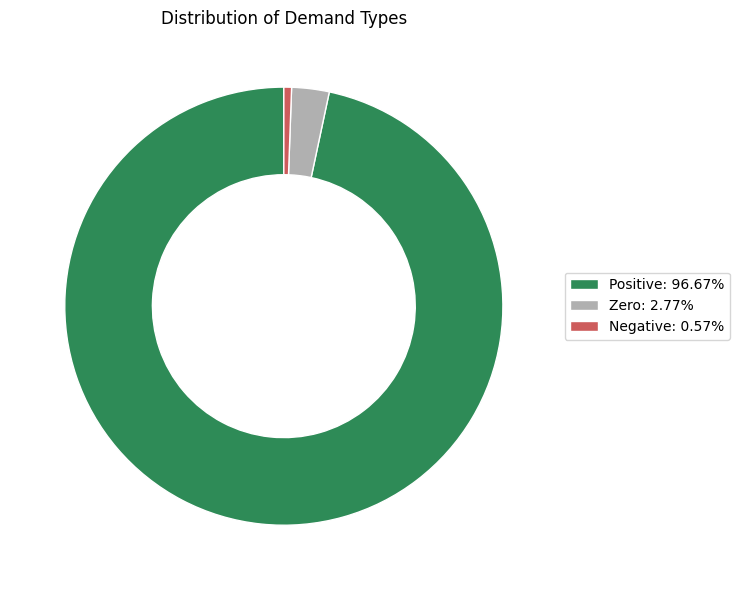

In [50]:
plt.figure(figsize=(8, 6))

plt.pie(
    demand_type['Count'],
    colors=['#2E8B57', '#B0B0B0', '#CD5C5C'],
    startangle=90,
    wedgeprops={'width': 0.4, 'edgecolor': 'white'}
)

labels = [
    f'{name}: {pct:.2f}%'
    for name, pct in demand_type['Percentage'].items()
]

plt.legend(labels, loc='center left', bbox_to_anchor=(1, 0.5))
plt.title('Distribution of Demand Types')
plt.tight_layout()
plt.show()

In [43]:
df_clean['Order_Demand'].describe().round(2)

count    1036643.00
mean        4915.91
std        29026.20
min      -999000.00
25%           19.00
50%          300.00
75%         2000.00
max      4000000.00
Name: Order_Demand, dtype: float64

In [44]:
df_clean['Order_Demand'].skew()

np.float64(31.380836205858895)

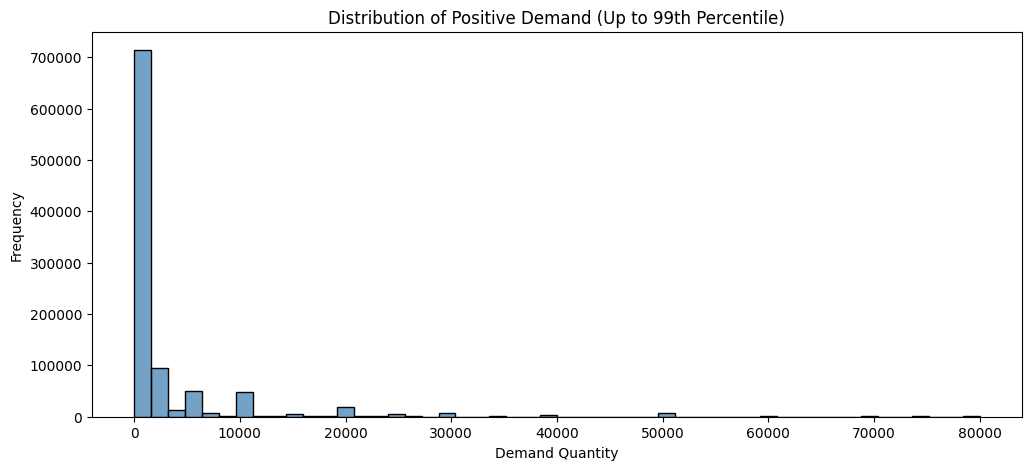

In [45]:
positive_demand = df_clean.loc[
    df_clean['Order_Demand'] > 0, 'Order_Demand'
]

upper_limit = positive_demand.quantile(0.99)

plt.figure(figsize=(12, 5))

sns.histplot(
    positive_demand[positive_demand <= upper_limit],
    bins=50,
    color='steelblue'
)

plt.title('Distribution of Positive Demand (Up to 99th Percentile)')
plt.xlabel('Demand Quantity')
plt.ylabel('Frequency')
plt.show()

In [46]:
Q1 = positive_demand.quantile(0.25)
Q3 = positive_demand.quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print('Q1:', Q1)
print('Q3:', Q3)
print('IQR:', IQR)
print('Upper Bound:', upper_bound)

Q1: 25.0
Q3: 2000.0
IQR: 1975.0
Upper Bound: 4962.5


In [47]:
outliers = df_clean[df_clean['Order_Demand'] > upper_bound]

print('Outlier Records:', len(outliers))

print('Outlier Percentage:',
      round(len(outliers) / len(positive_demand) * 100, 2))

Outlier Records: 179747
Outlier Percentage: 17.94


In [48]:
outlier_contribution = (
    outliers['Order_Demand'].sum() /
    positive_demand.sum()
) * 100

print('Outlier Demand Contribution:',
      round(outlier_contribution, 2))

Outlier Demand Contribution: 90.43


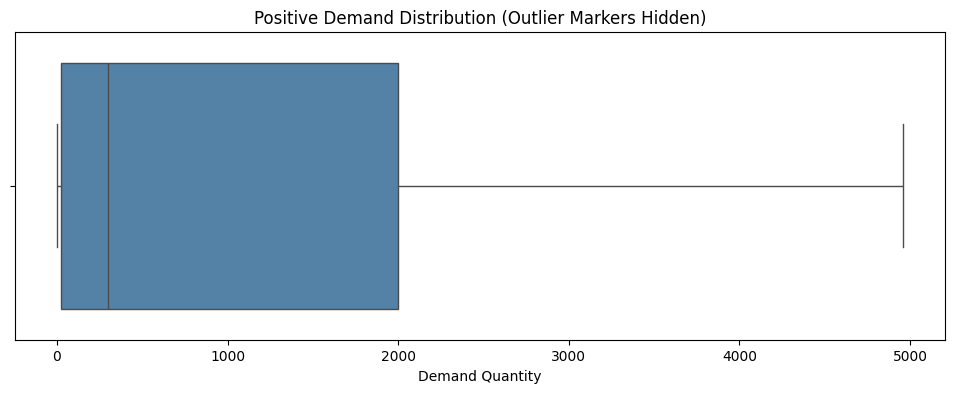

In [49]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    x=positive_demand,
    color='steelblue',
    showfliers=False
)

plt.title('Positive Demand Distribution (Outlier Markers Hidden)')
plt.xlabel('Demand Quantity')
plt.show()

### Key Findings from Univariate Analysis

- Positive demand represents 96.67% of all records, followed by zero demand at 2.77% and negative demand at 0.57%.
- The demand distribution is extremely right-skewed, with a skewness value of 31.38.
- The mean demand of 4,915.91 units is significantly higher than the median of 300 units, indicating the influence of large demand quantities.
- Using the IQR method on positive demand, quantities exceeding 4,962.5 units were identified as statistical high-demand outliers.
- A total of 179,747 records were identified as high-demand outliers, representing 17.94% of positive demand records.
- These records contribute 90.43% of total positive demand quantity, indicating a high concentration of demand volume.
- All outliers have been retained because removing them would result in a significant loss of demand information.

### Business Recommendations

- Use the median alongside the mean when reporting typical demand quantities.
- Investigate high-volume demand records across individual products, categories and warehouses.
- Avoid removing large demand quantities without business justification.
- Evaluate demand variability at the product level to support better inventory planning.

## 3.2 Bivariate Analysis

In [51]:
annual_demand = df_clean.groupby(
    df_clean['Date'].dt.year
)['Order_Demand'].sum().to_frame('Total_Demand')

annual_demand.index.name = 'Year'

annual_demand['YoY_Growth_%'] = (
    annual_demand['Total_Demand'].pct_change() * 100
).round(2)

annual_demand

,Total_Demand,YoY_Growth_%
Year,,
2012,941742907,NaN
2013,1009218798,7.17
2014,1064272479,5.46
2015,1095444965,2.93
2016,985368129,-10.05


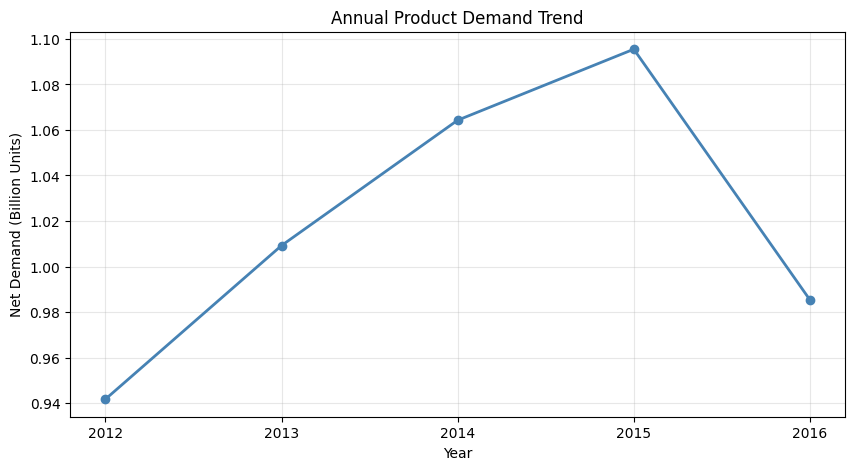

In [52]:
plt.figure(figsize=(10, 5))

plt.plot(
    annual_demand.index,
    annual_demand['Total_Demand'] / 1e9,
    marker='o',
    linewidth=2,
    color='steelblue'
)

plt.title('Annual Product Demand Trend')
plt.xlabel('Year')
plt.ylabel('Net Demand (Billion Units)')
plt.xticks(annual_demand.index)
plt.grid(alpha=0.3)
plt.show()

In [53]:
monthly_demand = df_clean.groupby(
    df_clean['Date'].dt.to_period('M')
)['Order_Demand'].sum()

monthly_demand.index = monthly_demand.index.to_timestamp()

monthly_demand.head()

Date
2012-01-01    74098835
2012-02-01    86471824
2012-03-01    85524550
2012-04-01    74292489
2012-05-01    85943287
Freq: MS, Name: Order_Demand, dtype: int64

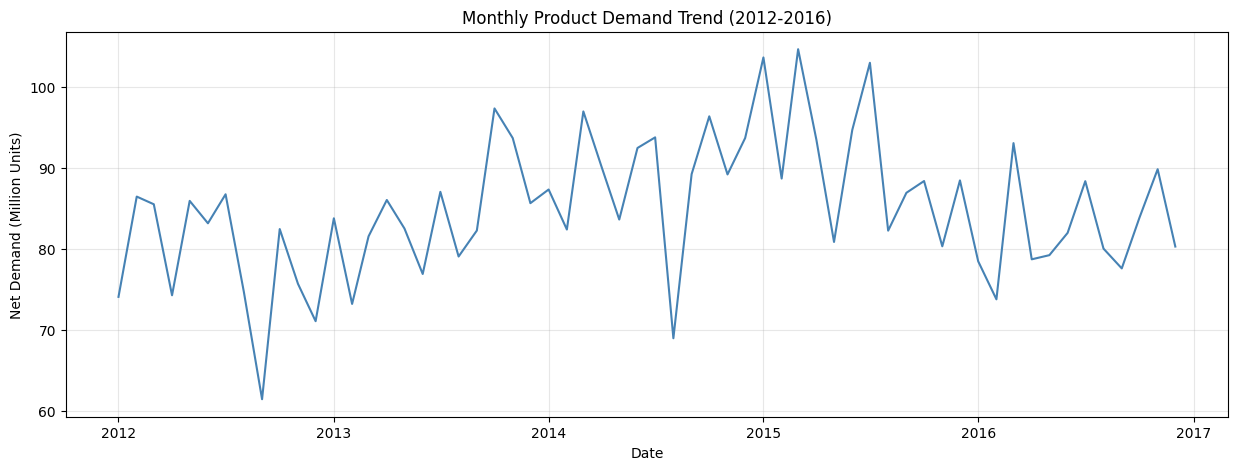

In [54]:
plt.figure(figsize=(15, 5))

plt.plot(
    monthly_demand.index,
    monthly_demand.values / 1e6,
    color='steelblue'
)

plt.title('Monthly Product Demand Trend (2012-2016)')
plt.xlabel('Date')
plt.ylabel('Net Demand (Million Units)')
plt.grid(alpha=0.3)
plt.show()

In [55]:
seasonal_demand = monthly_demand.groupby(
    monthly_demand.index.month
).mean().to_frame('Average_Monthly_Demand')

seasonal_demand.index = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

seasonal_demand.round(2)

,Average_Monthly_Demand
Jan,85474346.4
Feb,80919479.2
Mar,92359514.8
Apr,84542169.6
May,82447445.4
Jun,85850763.0
Jul,91790249.8
Aug,77023928.6
Sep,79508419.8
Oct,89687390.8


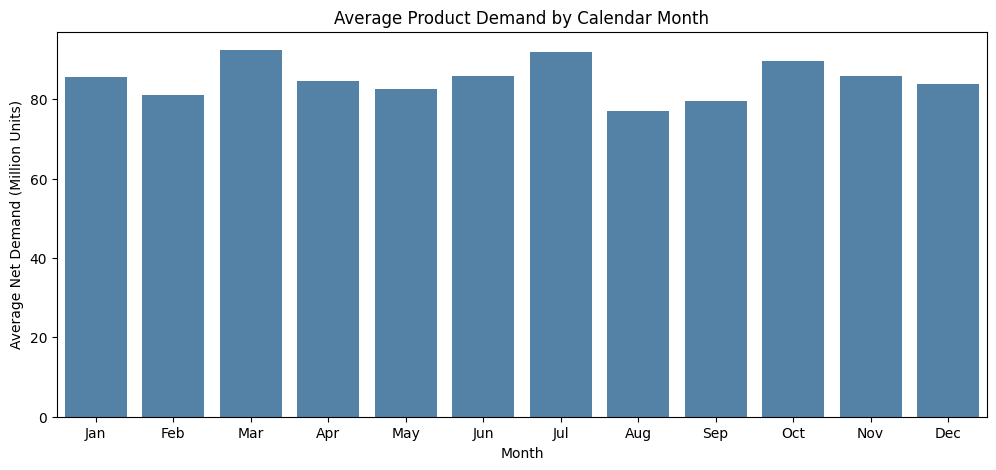

In [56]:
plt.figure(figsize=(12, 5))

sns.barplot(
    x=seasonal_demand.index,
    y=seasonal_demand['Average_Monthly_Demand'] / 1e6,
    color='steelblue'
)

plt.title('Average Product Demand by Calendar Month')
plt.xlabel('Month')
plt.ylabel('Average Net Demand (Million Units)')
plt.show()

In [57]:
print('Highest Demand Month:', monthly_demand.idxmax())
print('Highest Monthly Demand:', monthly_demand.max())

print('Lowest Demand Month:', monthly_demand.idxmin())
print('Lowest Monthly Demand:', monthly_demand.min())

Highest Demand Month: 2015-03-01 00:00:00
Highest Monthly Demand: 104654799
Lowest Demand Month: 2012-09-01 00:00:00
Lowest Monthly Demand: 61469157


### Key Findings from Time-Based Demand Analysis

- Annual net demand increased consistently between 2012 and 2015.
- The annual growth rate gradually declined from 7.17% in 2013 to 2.93% in 2015.
- The highest annual demand was recorded in 2015, reaching approximately 1.095 billion units.
- Demand declined by 10.05% in 2016, representing a reduction of approximately 110 million units compared to 2015.
- Monthly demand fluctuated considerably throughout the analysis period.
- March, July and October recorded the highest average monthly demand.
- August recorded the lowest average monthly demand, at approximately 77.02 million units.
- Historical monthly demand patterns can support inventory and warehouse capacity planning.

Further analysis is required to identify the products, categories and warehouses contributing to the demand decline in 2016 and to determine whether seasonal patterns are consistent across years.

In [58]:
quarterly_demand = monthly_demand.groupby(
    monthly_demand.index.to_period('Q')
).sum()

quarterly_avg = quarterly_demand.groupby(
    quarterly_demand.index.quarter
).mean().to_frame('Average_Quarterly_Demand')

quarterly_avg.index = ['Q1', 'Q2', 'Q3', 'Q4']

quarterly_avg.round(2)

,Average_Quarterly_Demand
Q1,258753340.4
Q2,252840378.0
Q3,248322598.2
Q4,259293139.0


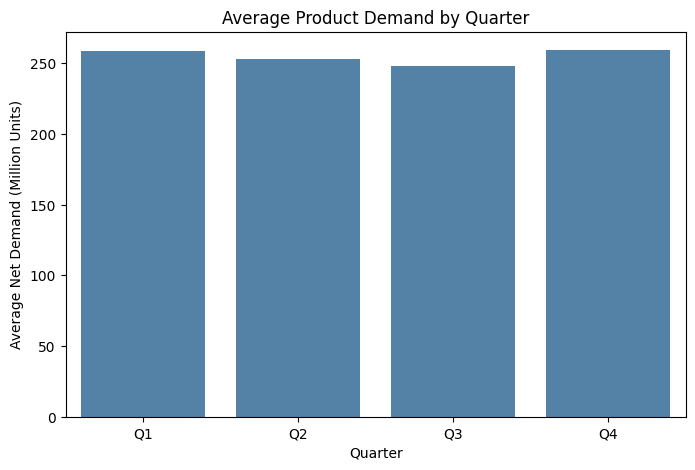

In [59]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=quarterly_avg.index,
    y=quarterly_avg['Average_Quarterly_Demand'] / 1e6,
    color='steelblue'
)

plt.title('Average Product Demand by Quarter')
plt.xlabel('Quarter')
plt.ylabel('Average Net Demand (Million Units)')
plt.show()

In [60]:
warehouse_demand = df_clean.groupby('Warehouse').agg(
    Total_Demand=('Order_Demand', 'sum'),
    Total_Records=('Order_Demand', 'count'),
    Unique_Products=('Product_Code', 'nunique'),
    Average_Demand=('Order_Demand', 'mean'),
    Median_Demand=('Order_Demand', 'median')
).sort_values('Total_Demand', ascending=False)

warehouse_demand['Demand_Share_%'] = (
    warehouse_demand['Total_Demand'] /
    warehouse_demand['Total_Demand'].sum() * 100
)

warehouse_demand.round(2)

,Total_Demand,Total_Records,Unique_Products,Average_Demand,Median_Demand,Demand_Share_%
Warehouse,,,,,,
Whse_J,3344066262,764215,1625,4375.82,300.0,65.62
Whse_S,1030165015,88024,553,11703.23,500.0,20.21
Whse_C,578777987,42207,244,13712.84,1000.0,11.36
Whse_A,143038014,142197,427,1005.91,50.0,2.81


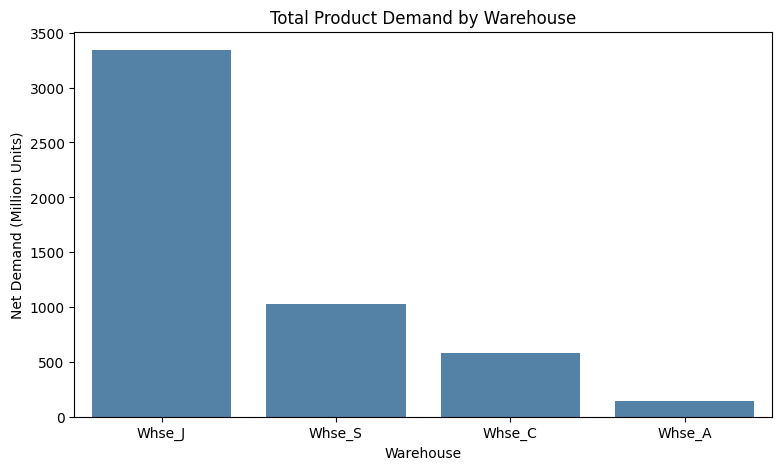

In [61]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=warehouse_demand.index,
    y=warehouse_demand['Total_Demand'] / 1e6,
    color='steelblue'
)

plt.title('Total Product Demand by Warehouse')
plt.xlabel('Warehouse')
plt.ylabel('Net Demand (Million Units)')
plt.show()

In [62]:
category_demand = df_clean.groupby('Product_Category').agg(
    Total_Demand=('Order_Demand', 'sum'),
    Total_Records=('Order_Demand', 'count'),
    Unique_Products=('Product_Code', 'nunique')
).sort_values('Total_Demand', ascending=False)

category_demand['Demand_Share_%'] = (
    category_demand['Total_Demand'] /
    category_demand['Total_Demand'].sum() * 100
)

category_demand.round(2)

,Total_Demand,Total_Records,Unique_Products,Demand_Share_%
Product_Category,,,,
Category_019,4213068570,470090,534,82.67
Category_006,401219159,35495,112,7.87
Category_005,197679740,101582,185,3.88
Category_007,127696217,82348,141,2.51
Category_028,47169520,30957,57,0.93
Category_033,42370000,1849,4,0.83
Category_030,40024855,12978,99,0.79
Category_032,4424920,9288,49,0.09
Category_021,4340660,51950,143,0.09


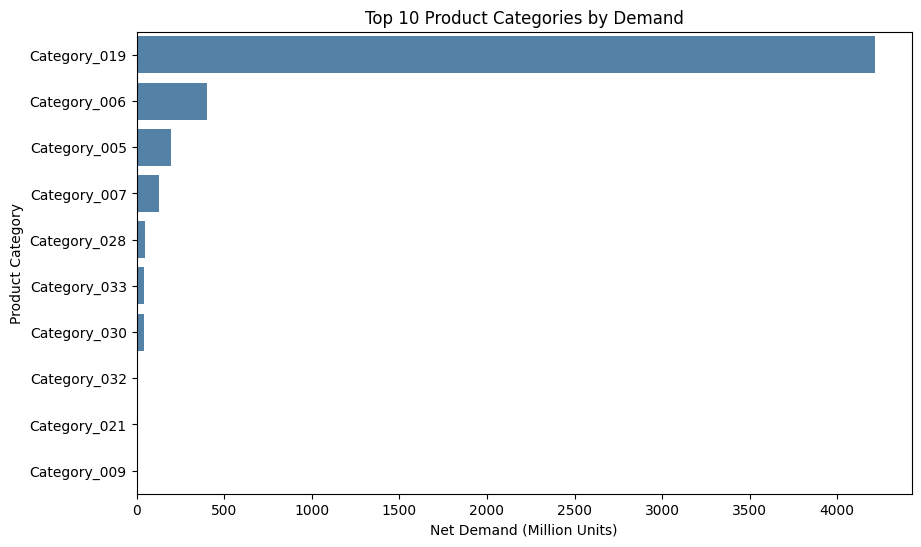

In [63]:
top_categories = category_demand.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_categories['Total_Demand'] / 1e6,
    y=top_categories.index,
    color='steelblue'
)

plt.title('Top 10 Product Categories by Demand')
plt.xlabel('Net Demand (Million Units)')
plt.ylabel('Product Category')
plt.show()

In [64]:
product_demand = df_clean.groupby('Product_Code').agg(
    Total_Demand=('Order_Demand', 'sum'),
    Total_Records=('Order_Demand', 'count'),
    Warehouses=('Warehouse', 'nunique')
).sort_values('Total_Demand', ascending=False)

product_demand.head(10)

,Total_Demand,Total_Records,Warehouses
Product_Code,,,
Product_1359,470610000,16935,1
Product_1248,288927000,6348,1
Product_0083,210427000,1987,3
Product_1341,166411000,2657,2
Product_1295,121992000,10575,1
Product_1241,115323000,5471,3
Product_1245,102037000,568,2
Product_1286,101331800,8888,1
Product_1432,96827000,2992,4


In [65]:
product_demand.tail(10).sort_values('Total_Demand')

,Total_Demand,Total_Records,Warehouses
Product_Code,,,
Product_1698,2,2,1
Product_1703,2,1,1
Product_0465,3,1,1
Product_0466,15,4,1
Product_0647,19,11,1
Product_0853,20,1,1
Product_1863,22,20,1
Product_0638,22,14,1
Product_1793,24,10,1


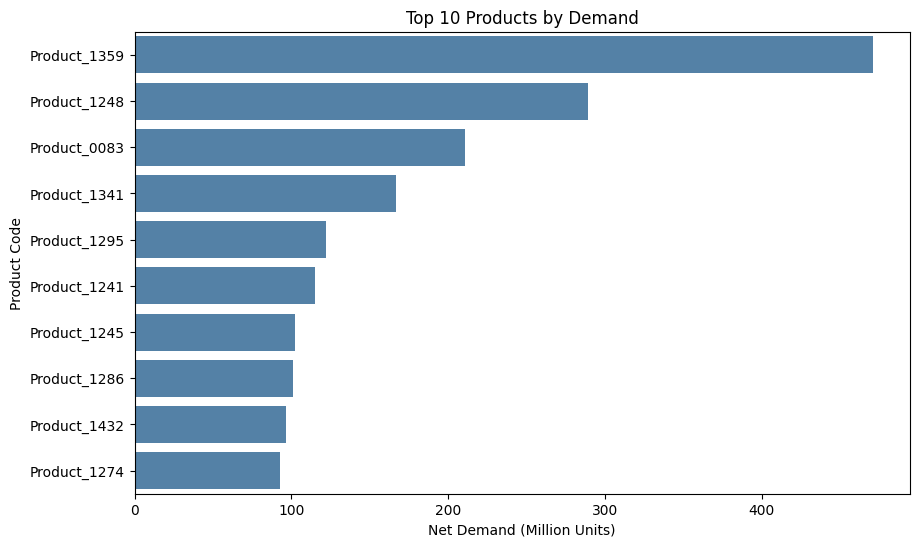

In [66]:
top_products = product_demand.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_products['Total_Demand'] / 1e6,
    y=top_products.index,
    color='steelblue'
)

plt.title('Top 10 Products by Demand')
plt.xlabel('Net Demand (Million Units)')
plt.ylabel('Product Code')
plt.show()

### Key Findings from Warehouse, Category and Product Demand Analysis

- March 2015 recorded the highest monthly demand at 104.65 million units, while September 2012 recorded the lowest at 61.47 million units.
- Q4 recorded the highest average quarterly demand, followed closely by Q1.
- Whse_J contributes 65.62% of total net demand and handles the largest product range of 1,625 products.
- Whse_C has the highest average demand per record at 13,712.84 units despite having the fewest records.
- Whse_A has the lowest total demand contribution at 2.81%.
- Category_019 dominates overall demand, contributing 82.67% of total net demand.
- The top four product categories account for approximately 96.93% of overall net demand.
- Product_1359 is the highest-demand product, with a total net demand of 470.61 million units.
- Several high-demand products have demand records concentrated within a single warehouse.

### Business Recommendations

- Prioritise demand monitoring and inventory planning for Category_019 and high-volume products.
- Adjust warehouse planning according to demand frequency and quantity.
- Investigate the concentration of high-demand products within individual warehouses.
- Use monthly demand patterns alongside quarterly averages for resource planning.

## 3.3 Multivariate Analysis

In [67]:
year_month = df_clean.pivot_table(
    index=df_clean['Date'].dt.year,
    columns=df_clean['Date'].dt.month,
    values='Order_Demand',
    aggfunc='sum'
)

year_month.columns = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

year_month

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Date,,,,,,,,,,,,
2012,74098835,86471824,85524550,74292489,85943287,83176613,86756369,74733539,61469157,82467309,75711993,71096942
2013,83795041,73226231,81571382,86051545,82531803,76921976,87059299,79077696,82282652,97349830,93690985,85660358
2014,87346247,82407630,96978683,90136672,83641063,92468368,93779582,68990673,89241160,96374721,89205758,93701922
2015,103641738,88697524,104654799,93498428,80876539,94690435,102982657,82268307,86939064,88390907,80336440,88468127
2016,78489871,73794187,93068160,78731714,79244535,81996423,88373342,80049428,77610066,83854187,89849906,80306310


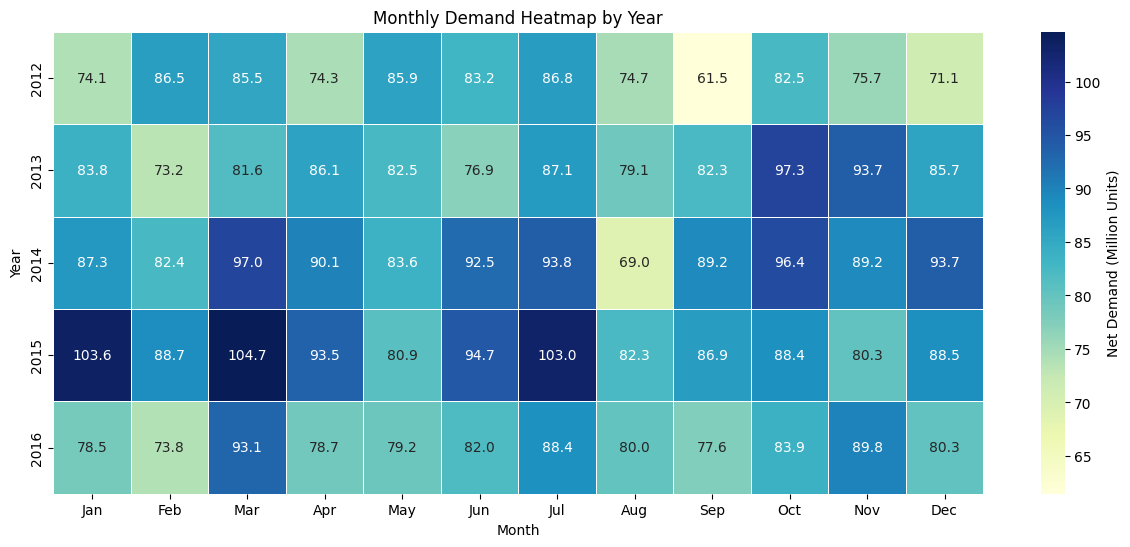

In [68]:
plt.figure(figsize=(15, 6))

sns.heatmap(
    year_month / 1e6,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Net Demand (Million Units)'}
)

plt.title('Monthly Demand Heatmap by Year')
plt.xlabel('Month')
plt.ylabel('Year')
plt.show()

In [69]:
warehouse_year = df_clean.pivot_table(
    index=df_clean['Date'].dt.year,
    columns='Warehouse',
    values='Order_Demand',
    aggfunc='sum'
)

warehouse_year

Warehouse,Whse_A,Whse_C,Whse_J,Whse_S
Date,,,,
2012,28298540,94596073,611270559,207577735
2013,27866100,109938491,661775416,209638791
2014,28879054,118245964,691259773,225887688
2015,28995542,125149312,697430144,243869967
2016,28998778,130848147,682330370,143190834


In [70]:
warehouse_growth = (
    warehouse_year.pct_change() * 100
).round(2)

warehouse_growth

Warehouse,Whse_A,Whse_C,Whse_J,Whse_S
Date,,,,
2012,NaN,NaN,NaN,NaN
2013,-1.53,16.22,8.26,0.99
2014,3.64,7.56,4.46,7.75
2015,0.40,5.84,0.89,7.96
2016,0.01,4.55,-2.17,-41.28


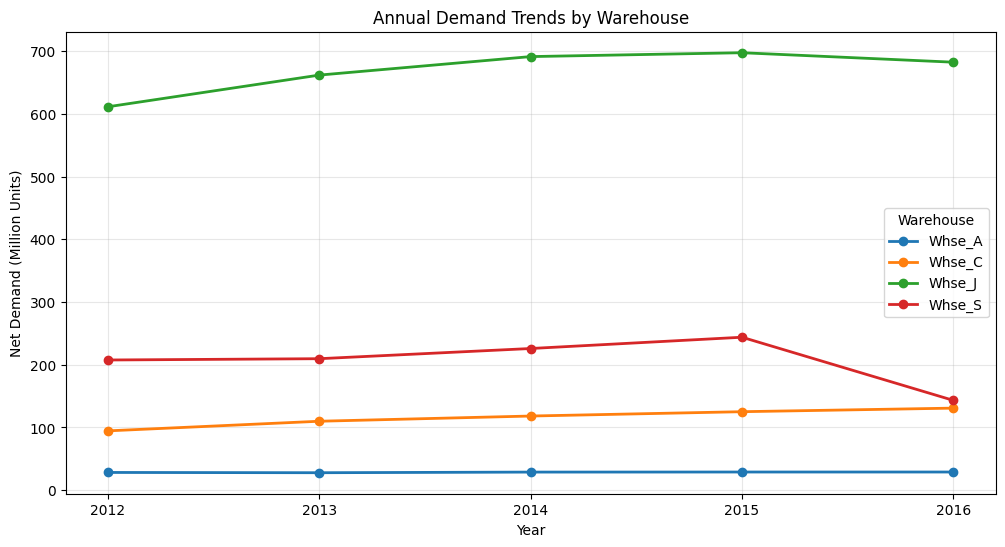

In [71]:
(warehouse_year / 1e6).plot(
    kind='line',
    figsize=(12, 6),
    marker='o',
    linewidth=2
)

plt.title('Annual Demand Trends by Warehouse')
plt.xlabel('Year')
plt.ylabel('Net Demand (Million Units)')
plt.xticks(warehouse_year.index)
plt.grid(alpha=0.3)
plt.legend(title='Warehouse')
plt.show()

In [72]:
warehouse_decline = warehouse_year.loc[[2015, 2016]].T.copy()

warehouse_decline.columns = ['Demand_2015', 'Demand_2016']

warehouse_decline['Demand_Change'] = (
    warehouse_decline['Demand_2016'] -
    warehouse_decline['Demand_2015']
)

warehouse_decline['Change_%'] = (
    warehouse_decline['Demand_Change'] /
    warehouse_decline['Demand_2015'] * 100
).round(2)

warehouse_decline.sort_values('Demand_Change')

,Demand_2015,Demand_2016,Demand_Change,Change_%
Warehouse,,,,
Whse_S,243869967,143190834,-100679133,-41.28
Whse_J,697430144,682330370,-15099774,-2.17
Whse_A,28995542,28998778,3236,0.01
Whse_C,125149312,130848147,5698835,4.55


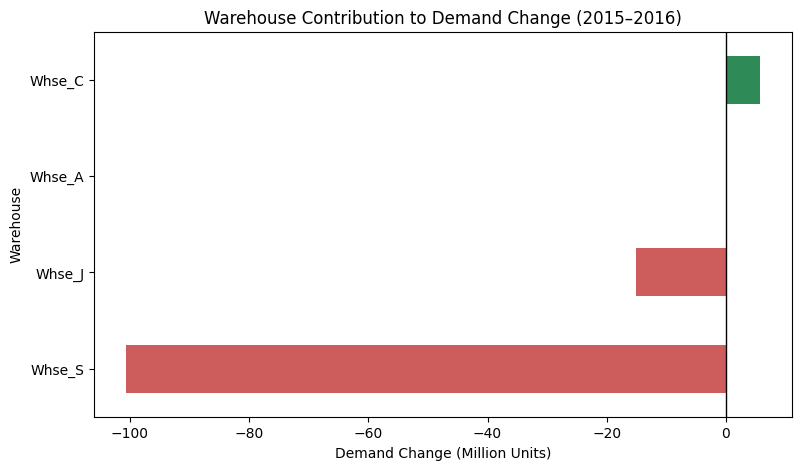

In [73]:
changes = warehouse_decline['Demand_Change'].sort_values() / 1e6

colors = ['indianred' if x < 0 else 'seagreen' for x in changes]

plt.figure(figsize=(9, 5))

changes.plot(kind='barh', color=colors)

plt.axvline(0, color='black', linewidth=1)
plt.title('Warehouse Contribution to Demand Change (2015–2016)')
plt.xlabel('Demand Change (Million Units)')
plt.ylabel('Warehouse')
plt.show()

In [74]:
category_year = df_clean.pivot_table(
    index='Product_Category',
    columns=df_clean['Date'].dt.year,
    values='Order_Demand',
    aggfunc='sum',
    fill_value=0
)

category_decline = category_year[[2015, 2016]].copy()

category_decline.columns = ['Demand_2015', 'Demand_2016']

category_decline['Demand_Change'] = (
    category_decline['Demand_2016'] -
    category_decline['Demand_2015']
)

category_decline['Change_%'] = (
    category_decline['Demand_Change'] /
    category_decline['Demand_2015'].replace(0, np.nan) * 100
).round(2)

category_decline.sort_values('Demand_Change').head(10)

,Demand_2015,Demand_2016,Demand_Change,Change_%
Product_Category,,,,
Category_019,896761793,814447055,-82314738,-9.18
Category_006,92024761,80501118,-11523643,-12.52
Category_005,45211000,38029805,-7181195,-15.88
Category_030,9767314,6846385,-2920929,-29.91
Category_007,25688905,22803958,-2884947,-11.23
Category_028,11431120,9177879,-2253241,-19.71
Category_009,875701,426933,-448768,-51.25
Category_020,660145,246787,-413358,-62.62
Category_032,1065136,705194,-359942,-33.79


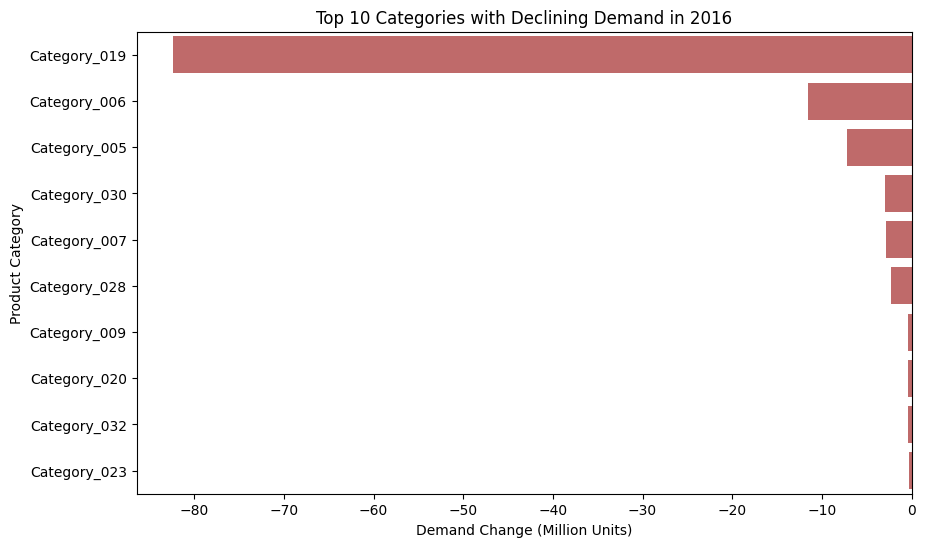

In [75]:
declining_categories = category_decline[
    category_decline['Demand_Change'] < 0
].sort_values('Demand_Change').head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=declining_categories['Demand_Change'] / 1e6,
    y=declining_categories.index,
    color='indianred'
)

plt.title('Top 10 Categories with Declining Demand in 2016')
plt.xlabel('Demand Change (Million Units)')
plt.ylabel('Product Category')
plt.show()

### Key Findings from Multivariate Analysis

- March recorded the highest monthly demand for three consecutive years between 2014 and 2016.
- August consistently recorded lower demand than July throughout the analysis period.
- Whse_C demonstrated consistent annual demand growth, although its growth rate gradually slowed.
- Whse_S experienced a significant demand decline of 41.28% in 2016, equivalent to approximately 100.68 million units.
- Whse_J experienced a moderate demand decline of 2.17% in 2016.
- Whse_C recorded positive growth of 4.55% in 2016, partially offsetting the decline in other warehouses.
- Category_019 recorded the largest absolute demand reduction of 82.31 million units in 2016.
- Category_006 and Category_005 were the next largest contributors to the category-level demand decline.

### Business Recommendations

- Investigate the significant demand decline at Whse_S.
- Prioritise Category_019 when reviewing changes in overall demand.
- Examine warehouse and product-level demand patterns before making inventory planning decisions.
- Consider both absolute demand changes and percentage growth when evaluating business performance.

The analysis identifies the segments contributing to the demand decline but cannot establish its underlying causes without additional business information.

In [76]:
warehouse_category_year = df_clean.pivot_table(
    index=['Warehouse', 'Product_Category'],
    columns=df_clean['Date'].dt.year,
    values='Order_Demand',
    aggfunc='sum',
    fill_value=0
)

wc_decline = warehouse_category_year[[2015, 2016]].copy()

wc_decline.columns = ['Demand_2015', 'Demand_2016']

wc_decline['Demand_Change'] = (
    wc_decline['Demand_2016'] -
    wc_decline['Demand_2015']
)

wc_decline['Change_%'] = (
    wc_decline['Demand_Change'] /
    wc_decline['Demand_2015'].replace(0, np.nan) * 100
).round(2)

wc_decline.sort_values('Demand_Change').head(10)

Demand_2015  Demand_2016  Demand_Change  Change_%
Warehouse Product_Category                                                   
Whse_S    Category_019        202014830    124475302      -77539528    -38.38
Whse_J    Category_019        564296121    554656913       -9639208     -1.71
Whse_S    Category_006         11846818      2310293       -9536525    -80.50
          Category_005         14248000      9020400       -5227600    -36.69
Whse_J    Category_006         70760117     67166042       -3594075     -5.08
Whse_S    Category_030          7983950      5305650       -2678300    -33.55
          Category_028          3211415      1053312       -2158103    -67.20
Whse_J    Category_005         28230900     26313405       -1917495     -6.79
Whse_S    Category_007          1625890        29696       -1596194    -98.17
Whse_J    Category_007         21798558     20410808       -1387750     -6.37

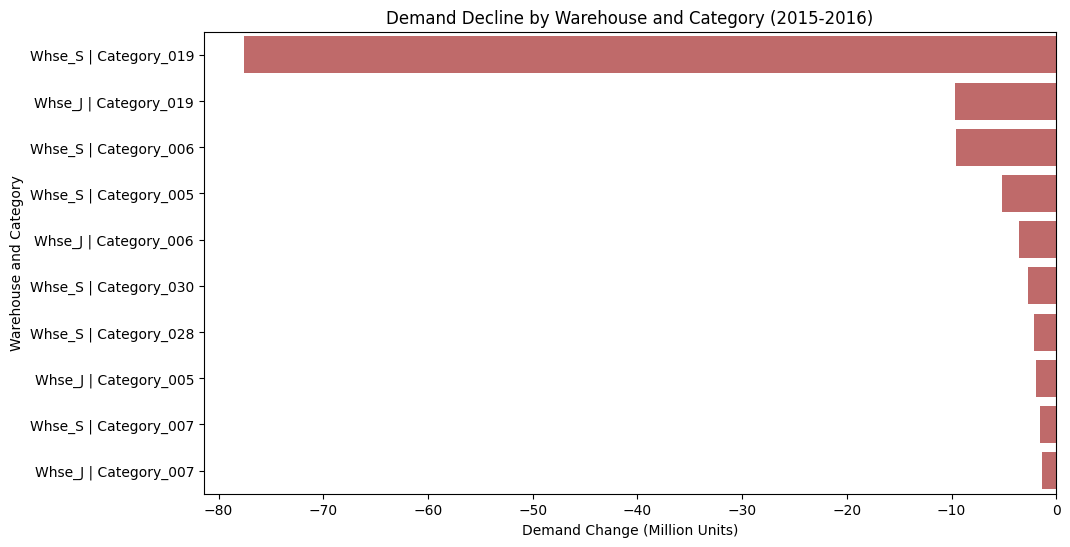

In [77]:
top_decline = wc_decline.sort_values(
    'Demand_Change'
).head(10).reset_index()

top_decline['Segment'] = (
    top_decline['Warehouse'] + ' | ' +
    top_decline['Product_Category']
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_decline,
    x=top_decline['Demand_Change'] / 1e6,
    y='Segment',
    color='indianred'
)

plt.title('Demand Decline by Warehouse and Category (2015-2016)')
plt.xlabel('Demand Change (Million Units)')
plt.ylabel('Warehouse and Category')
plt.show()

In [78]:
whse_s = df_clean[df_clean['Warehouse'] == 'Whse_S']

whse_s_products = whse_s.pivot_table(
    index='Product_Code',
    columns=whse_s['Date'].dt.year,
    values='Order_Demand',
    aggfunc='sum',
    fill_value=0
)

product_decline = whse_s_products[[2015, 2016]].copy()

product_decline.columns = ['Demand_2015', 'Demand_2016']

product_decline['Demand_Change'] = (
    product_decline['Demand_2016'] -
    product_decline['Demand_2015']
)

product_decline['Change_%'] = (
    product_decline['Demand_Change'] /
    product_decline['Demand_2015'].replace(0, np.nan) * 100
).round(2)

product_decline.sort_values('Demand_Change').head(10)

,Demand_2015,Demand_2016,Demand_Change,Change_%
Product_Code,,,,
Product_1341,27900000,8272000,-19628000,-70.35
Product_1567,11469000,1152000,-10317000,-89.96
Product_1393,6881000,522000,-6359000,-92.41
Product_1574,10809500,5774500,-5035000,-46.58
Product_1431,7098000,3054000,-4044000,-56.97
Product_1241,7452000,3461000,-3991000,-53.56
Product_1245,4783000,1662000,-3121000,-65.25
Product_1394,2803000,204000,-2599000,-92.72
Product_0936,2562500,525000,-2037500,-79.51


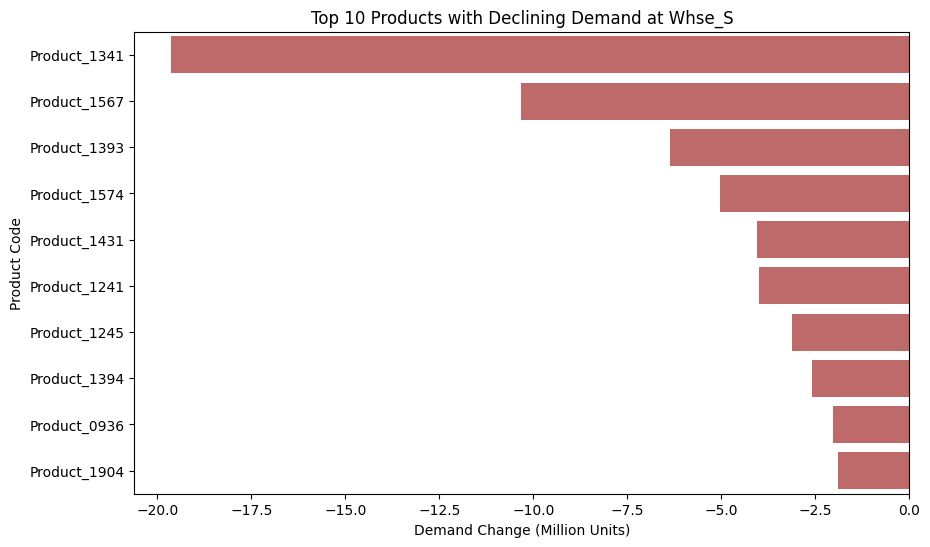

In [79]:
top_product_decline = product_decline.sort_values(
    'Demand_Change'
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_product_decline['Demand_Change'] / 1e6,
    y=top_product_decline.index,
    color='indianred'
)

plt.title('Top 10 Products with Declining Demand at Whse_S')
plt.xlabel('Demand Change (Million Units)')
plt.ylabel('Product Code')
plt.show()

In [80]:
warehouse_month = df_clean.groupby([
    'Warehouse',
    df_clean['Date'].dt.year,
    df_clean['Date'].dt.month
])['Order_Demand'].sum()

warehouse_seasonality = warehouse_month.groupby(
    level=[0, 2]
).mean().unstack()

warehouse_seasonality.columns = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

warehouse_seasonality.round(2)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Warehouse,,,,,,,,,,,,
Whse_A,2156020.8,2438061.0,2392358.6,2243453.2,2588584.8,2224091.2,2589761.6,2556498.0,2417106.0,2322085.4,2453608.4,2225973.8
Whse_C,8954785.4,7495480.2,10994733.6,9997654.0,9435181.6,9641526.2,11540570.2,9429745.2,9213973.0,9724418.6,9637768.8,9689760.6
Whse_J,54781096.8,55358998.2,58432951.4,55741314.0,51958090.2,56637198.0,59651401.8,49566933.0,53684662.2,60272725.6,57660973.0,55066908.2
Whse_S,19582443.4,15626939.8,20539471.2,16559748.4,18465588.8,17347947.6,18008516.2,15470752.4,14192678.6,17368161.2,16006666.2,16864089.2


In [81]:
seasonal_index = warehouse_seasonality.div(
    warehouse_seasonality.mean(axis=1),
    axis=0
) * 100

seasonal_index.round(2)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Warehouse,,,,,,,,,,,,
Whse_A,90.44,102.27,100.35,94.11,108.58,93.29,108.63,107.24,101.39,97.40,102.92,93.37
Whse_C,92.83,77.70,113.98,103.64,97.81,99.95,119.64,97.76,95.52,100.81,99.91,100.45
Whse_J,98.29,99.33,104.84,100.01,93.22,101.62,107.03,88.93,96.32,108.14,103.46,98.80
Whse_S,114.05,91.02,119.63,96.45,107.55,101.04,104.89,90.11,82.66,101.16,93.23,98.22


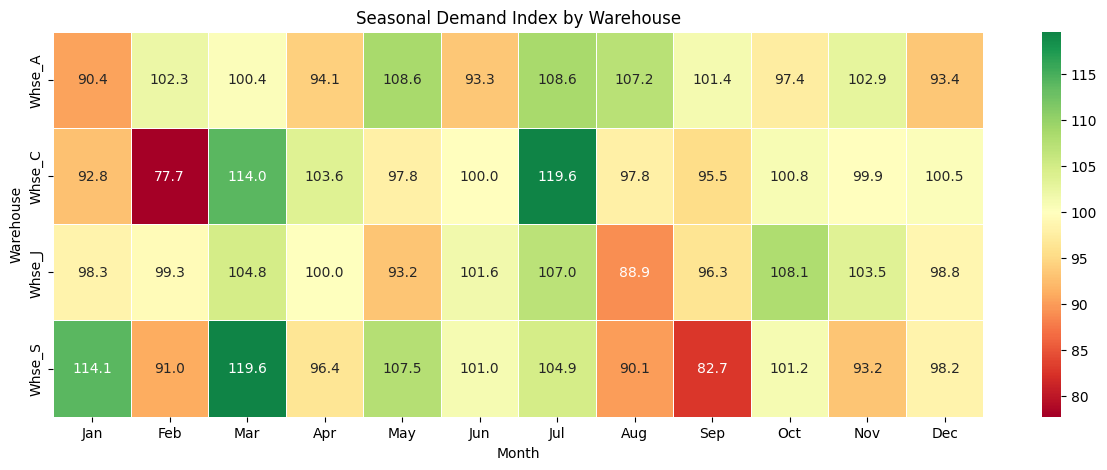

In [82]:
plt.figure(figsize=(15, 5))

sns.heatmap(
    seasonal_index,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    center=100,
    linewidths=0.5
)

plt.title('Seasonal Demand Index by Warehouse')
plt.xlabel('Month')
plt.ylabel('Warehouse')
plt.show()

In [83]:
negative_demand = df_clean[
    df_clean['Order_Demand'] < 0
]

negative_summary = negative_demand.groupby('Warehouse').agg(
    Negative_Records=('Order_Demand', 'count'),
    Negative_Quantity=('Order_Demand', 'sum')
)

negative_summary['Total_Records'] = (
    warehouse_demand['Total_Records']
)

negative_summary['Negative_Record_Rate_%'] = (
    negative_summary['Negative_Records'] /
    negative_summary['Total_Records'] * 100
).round(2)

negative_summary['Negative_Quantity'] = (
    negative_summary['Negative_Quantity'].abs()
)

negative_summary.sort_values(
    'Negative_Record_Rate_%',
    ascending=False
)

,Negative_Records,Negative_Quantity,Total_Records,Negative_Record_Rate_%
Warehouse,,,,
Whse_A,1815,2304268,142197,1.28
Whse_J,3547,9338134,764215,0.46
Whse_S,380,1478398,88024,0.43
Whse_C,117,1613096,42207,0.28


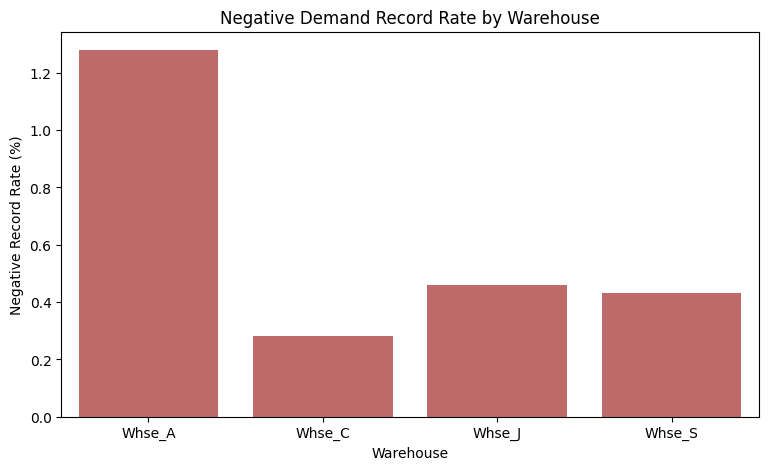

In [84]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    x=negative_summary.index,
    y=negative_summary['Negative_Record_Rate_%'],
    color='indianred',
    ax=ax
)

plt.title('Negative Demand Record Rate by Warehouse')
plt.xlabel('Warehouse')
plt.ylabel('Negative Record Rate (%)')
plt.show()

### Key Findings from Advanced Multivariate Analysis

- Category_019 at Whse_S recorded the largest warehouse-category demand reduction of 77.54 million units in 2016.
- Category_006 and Category_007 at Whse_S experienced demand declines of 80.50% and 98.17%, respectively.
- Product_1341 recorded the largest product-level demand reduction at Whse_S, declining by 19.63 million units.
- Seasonal demand patterns differ across warehouses, indicating the need for warehouse-specific planning.
- Whse_C and Whse_A recorded their highest seasonal demand in July, while Whse_J and Whse_S recorded their peaks in October and March, respectively.
- Whse_A recorded the highest negative demand record rate of 1.28%.
- Whse_J recorded the highest absolute negative demand quantity of approximately 9.34 million units.

### Business Recommendations

- Investigate declining demand at Whse_S, particularly within Category_019.
- Review demand changes for Product_1341, Product_1567 and Product_1393.
- Develop warehouse-specific seasonal inventory planning strategies.
- Investigate the high proportion of negative demand records and missing dates associated with Whse_A.
- Prioritise high-volume products and categories when reviewing inventory requirements.

### Limitations

The dataset does not contain inventory levels, customer information, product costs, warehouse capacity or explanations for negative demand quantities. Therefore, the analysis identifies historical patterns and contributors to demand changes but does not establish their underlying business causes.

In [85]:
df_clean.to_csv('Cleaned_Product_Demand.csv', index=False)

In [86]:
pd.read_csv('Cleaned_Product_Demand.csv').shape

(1036643, 6)